# Results - PAD Dataset

In [6]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy.stats import spearmanr


In [ ]:
# --- Data paths ---
RAW_OA_DATA = "oa_us_pipeline_data/2025-08-12_16-25-11/data/.extraction/intensity_extraction_RAW_DATA_MUSCLE.xlsx"
FC_OA_DATA  = "oa_us_pipeline_data/2025-08-12_16-25-11/data/.extraction/intensity_extraction_FC_MUSCLE.xlsx"

# --- Classification results (ROC-AUC with 95% CI, taken from OA US Analysis Pipeline 2025-08-12_16-25-11 ---
cl_res_raw = [["0.81 [CI: 0.71, 0.89]"], ["0.63 [CI: 0.53, 0.73]"], ["0.88 [CI: 0.80, 0.94]"]]
cl_res_fc  = [["0.82 [CI: 0.72, 0.89]"], ["0.74 [CI: 0.64, 0.83]"], ["0.87 [CI: 0.79, 0.93]"]]
cl_columns = ["ROC-AUC"]
cl_rows    = ["Hb", "HbO2", "mSO2"]

# --- Plot settings ---
x_lim   = (15, 30)   # depth range in mm
y_range = (-0.2, 1.2)

plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 12,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
})


In [21]:
def load_channel(path, sheet):
    df = pd.read_excel(path, sheet_name=sheet)
    return df["roi-centroid-z"].values, df["original_firstorder_Mean"].values

def minmax(x):
    return (x - x.min()) / (x.max() - x.min())

pos_hb,   raw_hb   = load_channel(RAW_OA_DATA, "Hb")
pos_hbo2, raw_hbo2 = load_channel(RAW_OA_DATA, "HbO2")
_,        fc_hb    = load_channel(FC_OA_DATA,  "Hb")
_,        fc_hbo2  = load_channel(FC_OA_DATA,  "HbO2")

raw_hb, raw_hbo2, fc_hb, fc_hbo2 = map(minmax, [raw_hb, raw_hbo2, fc_hb, fc_hbo2])

pos_hb_mm   = pos_hb   * 1000
pos_hbo2_mm = pos_hbo2 * 1000

# Spearman correlations
rho_hb,      p_hb      = spearmanr(pos_hb,   raw_hb)
rho_hbo2,    p_hbo2    = spearmanr(pos_hbo2, raw_hbo2)
rho_hb_fc,   p_hb_fc   = spearmanr(pos_hb,   fc_hb)
rho_hbo2_fc, p_hbo2_fc = spearmanr(pos_hbo2, fc_hbo2)


/tmp/ipykernel_289230/514704385.py:53: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0.08, 0.05, 1, 0.9])


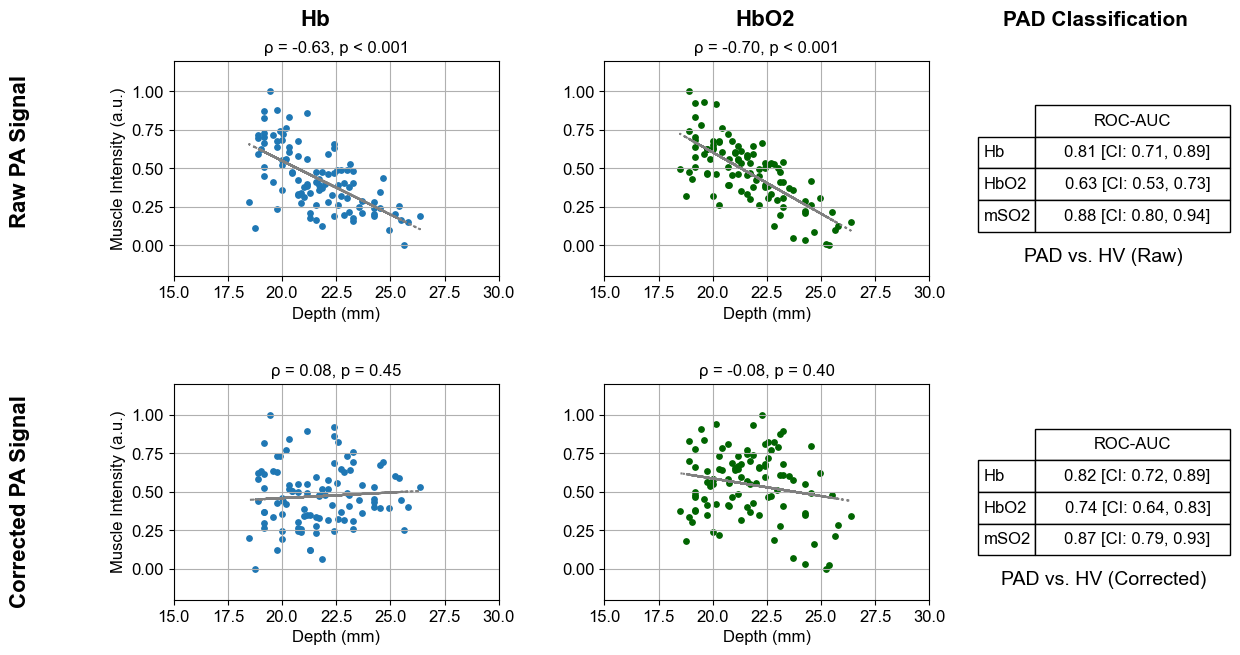

In [15]:
def spearman_label(rho, p):
    p_str = "p < 0.001" if p < 0.001 else f"p = {p:.2f}"
    return f"ρ = {rho:.2f}, {p_str}"

def scatter_with_trend(ax, x, y, color, ylabel=None):
    ax.scatter(x, y, s=15, color=color)
    slope, intercept = np.polyfit(x, y, 1)
    ax.plot(x, slope * x + intercept, color="gray", linestyle=":")
    ax.set_xlabel("Depth (mm)", fontsize=12)
    ax.set_xlim(x_lim)
    ax.set_ylim(y_range)
    ax.tick_params(axis='both', which='major', labelsize=12)
    ax.grid()
    if ylabel:
        ax.set_ylabel(ylabel, fontsize=12)

def add_table(ax, data, label):
    ax.axis("off")
    ax.text(0.35, 0.05, label, ha='center', va='bottom', fontsize=14, transform=ax.transAxes)
    t = ax.table(cellText=data, colLabels=cl_columns, rowLabels=cl_rows, loc='center')
    t.set_fontsize(12)
    t.scale(1.0, 1.9)


fig = plt.figure(figsize=(15, 7))
gs  = gridspec.GridSpec(2, 4, width_ratios=[0.001, 1, 1, 0.6], wspace=0.5, hspace=0.5)

fig.text(0.1,  0.75, "Raw PA Signal",       va='center', ha='right', rotation='vertical', fontsize=16, weight='bold')
fig.text(0.1,  0.25, "Corrected PA Signal", va='center', ha='right', rotation='vertical', fontsize=16, weight='bold')
fig.text(0.29, 0.93, "Hb",                  ha='center', fontsize=16, weight='bold')
fig.text(0.59, 0.93, "HbO2",                ha='center', fontsize=16, weight='bold')
fig.text(0.81, 0.93, "PAD Classification",  ha='center', fontsize=15, weight='bold')

ax1 = fig.add_subplot(gs[0, 1])
scatter_with_trend(ax1, pos_hb_mm,   raw_hb,   "C0",        ylabel="Muscle Intensity (a.u.)")
ax1.set_title(spearman_label(rho_hb, p_hb), fontsize=12)

ax2 = fig.add_subplot(gs[0, 2])
scatter_with_trend(ax2, pos_hbo2_mm, raw_hbo2, "darkgreen")
ax2.set_title(spearman_label(rho_hbo2, p_hbo2), fontsize=12)

ax3 = fig.add_subplot(gs[1, 1])
scatter_with_trend(ax3, pos_hb_mm,   fc_hb,    "C0",        ylabel="Muscle Intensity (a.u.)")
ax3.set_title(spearman_label(rho_hb_fc, p_hb_fc), fontsize=12)

ax4 = fig.add_subplot(gs[1, 2])
scatter_with_trend(ax4, pos_hbo2_mm, fc_hbo2,  "darkgreen")
ax4.set_title(spearman_label(rho_hbo2_fc, p_hbo2_fc), fontsize=12)

add_table(fig.add_subplot(gs[0, 3]), cl_res_raw, "PAD vs. HV (Raw)")
add_table(fig.add_subplot(gs[1, 3]), cl_res_fc,  "PAD vs. HV (Corrected)")

plt.tight_layout(rect=[0.08, 0.05, 1, 0.9])
os.makedirs("figures", exist_ok=True)
plt.savefig("figures/pad_results.pdf", bbox_inches='tight', dpi=300)
plt.show()
